<a href="https://colab.research.google.com/github/nwaryszak/APRAU/blob/Kornelia/APRAU_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Imports

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    KFold,
    LeaveOneOut,
    cross_validate,
    cross_val_predict
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

## 1. Data preparation

In [45]:
RANDOM_STATE = 42

# Load the dataset
df = pd.read_csv("dataset_grupo_06.csv")

print("Dataset shape:", df.shape)
display(df.head())

# Check targets
print("\nRegression target:")
display(df["target_regression"].describe())

print("\nClassification target:")
display(df["target_class"].value_counts())
display(
    (df["target_class"].value_counts(normalize=True) * 100)
    .round(2)
    .rename("percentage")
)

# Check missing values and constant features
print("\nTotal missing values:", df.isna().sum().sum())

constant_features = [
    col for col in df.columns
    if df[col].nunique(dropna=False) <= 1
]
print("Constant features:", constant_features)

Dataset shape: (2000, 35)


,age_level,gender,bmi_level,smoking,age,age_normalized,bmi,HbA1c_level,cholesterol,sleep_hours,...,hdl,ldl,education_level,employment_status,systolic_index,calcium_baseline,plasma_value,ldl_alternative,target_regression,target_class
0,Mature,Male,Obese,Current,58,0.643678,30.159257,5.436598,256.000000,6.867758,...,64.420845,129.290141,Primary,Employed,134.260845,9.42,1.100955,129.996562,117.0,HT_HY
1,Mature,Male,Overweight,Never,54,0.597701,29.527706,5.405745,274.000000,7.095850,...,65.304892,129.050057,Tertiary,Retired,134.392491,9.42,1.090490,129.878090,113.0,HT
2,Senior,Female,Overweight,Never,80,0.896552,27.320000,4.500000,229.436364,7.166333,...,64.516058,130.229236,Secondary,Unemployed,133.508306,9.42,1.154289,129.050057,80.0,HT
3,Senior,Male,Obese,Current,70,0.781609,35.130000,6.800000,226.554622,7.083442,...,65.224513,129.091365,Tertiary,Unemployed,134.283565,9.42,1.409238,130.545353,280.0,DI_HT_HY
4,Mature,Male,Obese,Never,52,0.574713,30.060476,5.443154,165.000000,6.387091,...,64.268197,130.545353,Primary,Employed,133.613102,9.42,1.226389,129.050057,138.0,HT_HY



Regression target:


,target_regression
count,2000.000000
mean,132.253761
std,38.172917
min,80.000000
25%,100.000000
50%,130.000000
75%,156.000000
max,300.000000



Classification target:


,count
target_class,
HT,1131
HT_HY,481
DI_HT_HY,388


,percentage
target_class,
HT,56.55
HT_HY,24.05
DI_HT_HY,19.40



Total missing values: 0
Constant features: ['calcium_baseline']


## 2. Predictors preparation

In [46]:
# Exclude both target variables from the predictors
target_columns = ["target_regression", "target_class"]

X = df.drop(columns=target_columns).copy()

# Remove constant columns
X = X.drop(columns=constant_features, errors="ignore")

# Target variables
y_reg = df["target_regression"]
y_class = df["target_class"]

# Identify numeric and categorical features
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

print("Number of numeric features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))
print("\nNumeric features:", numeric_features)
print("\nCategorical features:", categorical_features)

# Preprocessing for classification
clf_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numeric_features
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_features
        )
    ],
    remainder="drop"
)

Number of numeric features: 20
Number of categorical features: 12

Numeric features: ['age', 'age_normalized', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'blood_pressure', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'systolic_index', 'plasma_value', 'ldl_alternative']

Categorical features: ['age_level', 'gender', 'bmi_level', 'smoking', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'sugar_consumption', 'education_level', 'employment_status']


## Linear regression

### 3. Holdout — splitting into training and test sets

In [47]:
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X,
    y_reg,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Training set:", X_train_reg.shape)
print("Test set:", X_test_reg.shape)

Training set: (1600, 32)
Test set: (400, 32)


### 4. Simple linear regression — testing individual features

In [48]:
simple_regression_results = []

for feature in X.columns:
    is_num = pd.api.types.is_numeric_dtype(X[feature])

    if is_num:
        transformer = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ])
    else:
        transformer = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ])

    preprocessor = ColumnTransformer(
        transformers=[("feature", transformer, [feature])],
        remainder="drop"
    )

    model = Pipeline([
        ("preprocessing", preprocessor),
        ("regression", LinearRegression())
    ])

    model.fit(X_train_reg[[feature]], y_train_reg)
    predictions = model.predict(X_test_reg[[feature]])

    simple_regression_results.append({
        "feature": feature,
        "R2": r2_score(y_test_reg, predictions),
        "MAE": mean_absolute_error(y_test_reg, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test_reg, predictions))
    })

simple_regression_results = pd.DataFrame(simple_regression_results)

simple_regression_results = simple_regression_results.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

display(simple_regression_results.round(4))

,feature,R2,MAE,RMSE
0,smoking,0.0285,28.0358,37.3872
1,physical_activity,0.0196,27.9823,37.5582
2,HbA1c_level,0.0193,28.6394,37.5644
3,age,0.0155,28.0717,37.6372
4,age_normalized,0.0155,28.0717,37.6372
5,age_level,0.0123,28.2006,37.6990
6,low_hdl_cholesterol,0.0083,28.3649,37.7748
7,salt_intake,0.0076,28.3014,37.7874
8,hdl,0.0071,28.3931,37.7982
9,systolic_index,0.0065,28.3618,37.8090


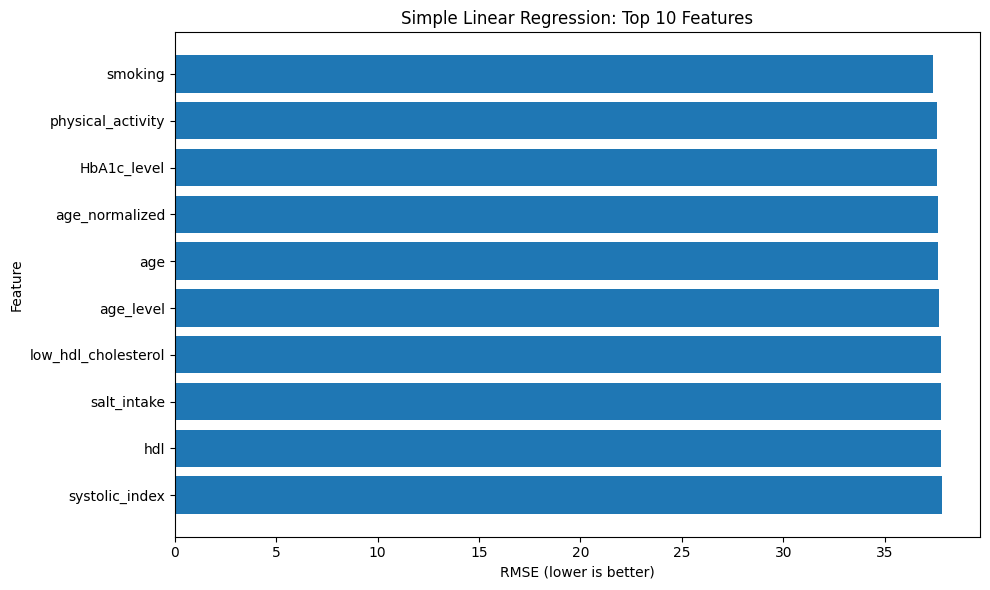

In [49]:
top_features = simple_regression_results.head(10).sort_values(
    "RMSE",
    ascending=False
)

plt.figure(figsize=(10, 6))
plt.barh(top_features["feature"], top_features["RMSE"])
plt.xlabel("RMSE (lower is better)")
plt.ylabel("Feature")
plt.title("Simple Linear Regression: Top 10 Features")
plt.tight_layout()
plt.show()

### Interpretation & Discussion of Simple Linear Regression
In this experiment, we trained individual linear regression models for each feature to evaluate their single-variable predictive power on `target_regression`.

**Key Observations:**
* **Best Single Predictor:** The features located at the top of the RMSE ranking (lowest error and highest $R^2$) demonstrate the strongest direct linear relationship with the target variable.
* **Model Limitations:** A single feature only captures a small fraction of the variance in `target_regression`. Most individual attributes yield relatively low $R^2$ values, indicating that predicting clinical biomarker concentrations accurately requires combining multiple clinical and demographic factors.

### 5. Multiple Linear Regression - Comparing Feature Sets
!!! TODO further

In [50]:
# Define initial feature groups
clinical_numeric_features = [
    "bmi", "HbA1c_level", "cholesterol", "sleep_hours",
    "triglycerides", "blood_pressure", "crp_level",
    "homocysteine_level", "systolic_bp", "diastolic_bp",
    "alcohol_intake", "salt_intake", "heart_rate",
    "hdl", "ldl", "systolic_index", "plasma_value",
    "ldl_alternative", "age", "age_normalized"
]

demographic_features = [
    "age", "age_level", "age_normalized", "gender",
    "education_level", "employment_status"
]

lifestyle_features = [
    "smoking", "physical_activity", "sleep_hours",
    "sugar_consumption", "alcohol_intake", "salt_intake",
    "stress_level"
]

# Keep only columns that actually exist in X
feature_sets = {
    "All available features": list(X.columns),
    "Numeric clinical features": [
        c for c in clinical_numeric_features if c in X.columns
    ],
    "Demographic features": [
        c for c in demographic_features if c in X.columns
    ],
    "Lifestyle features": [
        c for c in lifestyle_features if c in X.columns
    ]
}

multiple_regression_results = []

for set_name, features in feature_sets.items():
    if not features:
        continue

    subset_numeric = [c for c in features if pd.api.types.is_numeric_dtype(X[c])]
    subset_categorical = [c for c in features if not pd.api.types.is_numeric_dtype(X[c])]

    transformers = []

    if subset_numeric:
        transformers.append((
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            subset_numeric
        ))

    if subset_categorical:
        transformers.append((
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore"))
            ]),
            subset_categorical
        ))

    subset_preprocessor = ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )

    model = Pipeline([
        ("preprocessing", subset_preprocessor),
        ("regression", LinearRegression())
    ])

    model.fit(X_train_reg[features], y_train_reg)
    predictions = model.predict(X_test_reg[features])

    multiple_regression_results.append({
        "feature_set": set_name,
        "number_of_features": len(features),
        "R2": r2_score(y_test_reg, predictions),
        "MAE": mean_absolute_error(y_test_reg, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test_reg, predictions))
    })


multiple_regression_results = pd.DataFrame(multiple_regression_results)
multiple_regression_results = multiple_regression_results.sort_values(
    "RMSE"
).reset_index(drop=True)

display(multiple_regression_results.round(4))

,feature_set,number_of_features,R2,MAE,RMSE
0,All available features,32,0.0753,27.6108,36.4757
1,Numeric clinical features,20,0.0555,27.9293,36.8651
2,Lifestyle features,7,0.0472,27.3276,37.0264
3,Demographic features,6,0.0086,28.3196,37.7682


### Interpretation & Discussion of Multiple Linear Regression
We evaluated multiple linear regression models using different logical feature subsets (All features, Numeric Clinical, Demographic, and Lifestyle) to observe how feature diversity impacts performance.

**Key Observations:**
* **All Features vs. Subsets:** Including all available features achieved the best performance (lowest RMSE and highest $R^2$), outperforming any reduced domain-specific subset.
* **Domain Relevance:** Clinical numeric features (such as biomarkers and laboratory measurements) contributed significantly more to predictive performance than demographic or lifestyle attributes alone.
* **Conclusion:** Combining clinical biomarkers with demographic and lifestyle context creates a richer feature representation, improving overall regression accuracy compared to simple linear regression.

## Logistic Regression

### 6. Model preparation and holdout

Accuracy: 0.7
Balanced accuracy: 0.6225
Macro F1: 0.6086

Classification report:
              precision    recall  f1-score   support

    DI_HT_HY       0.89      0.86      0.88        78
          HT       0.68      0.89      0.78       226
       HT_HY       0.37      0.11      0.17        96

    accuracy                           0.70       400
   macro avg       0.65      0.62      0.61       400
weighted avg       0.65      0.70      0.65       400



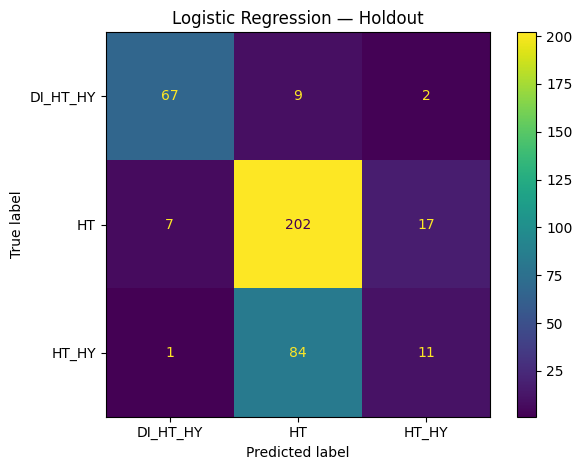

In [51]:
# Train-test split with stratification to preserve class proportions
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X,
    y_class,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_class
)

logistic_model = Pipeline([
    ("preprocessing", clf_preprocessor),
    ("classifier", LogisticRegression(
        max_iter=3000,
        random_state=RANDOM_STATE
    ))
])

logistic_model.fit(X_train_clf, y_train_clf)

y_pred_holdout = logistic_model.predict(X_test_clf)

print("Accuracy:", round(accuracy_score(y_test_clf, y_pred_holdout), 4))
print(
    "Balanced accuracy:",
    round(balanced_accuracy_score(y_test_clf, y_pred_holdout), 4)
)
print(
    "Macro F1:",
    round(f1_score(y_test_clf, y_pred_holdout, average="macro"), 4)
)

print("\nClassification report:")
print(classification_report(y_test_clf, y_pred_holdout, zero_division=0))

cm = confusion_matrix(
    y_test_clf,
    y_pred_holdout,
    labels=logistic_model.named_steps["classifier"].classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=logistic_model.named_steps["classifier"].classes_
)
disp.plot()
plt.title("Logistic Regression — Holdout")
plt.tight_layout()
plt.show()

### 7. Cross-validation — 5-fold i 10-fold

In [52]:
def make_logistic_model():
    return Pipeline([
        ("preprocessing", clf_preprocessor),
        ("classifier", LogisticRegression(
            max_iter=3000,
            random_state=RANDOM_STATE
        ))
    ])


scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "macro_f1": "f1_macro"
}

cv_results = []

for k in [5, 10]:
    cv = StratifiedKFold(
        n_splits=k,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    model = make_logistic_model()

    scores = cross_validate(
        model,
        X,
        y_class,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    for metric in scoring:
        values = scores[f"test_{metric}"]

        cv_results.append({
            "method": f"{k}-fold CV",
            "metric": metric,
            "mean": values.mean(),
            "std": values.std(ddof=1)
        })

cv_results = pd.DataFrame(cv_results)
display(cv_results.round(4))

,method,metric,mean,std
0,5-fold CV,accuracy,0.6970,0.0164
1,5-fold CV,balanced_accuracy,0.6155,0.0201
2,5-fold CV,macro_f1,0.6009,0.0187
3,10-fold CV,accuracy,0.6925,0.0172
4,10-fold CV,balanced_accuracy,0.6096,0.0236
5,10-fold CV,macro_f1,0.5920,0.0285


### 8. LOOCV — Leave-One-Out Cross-Validation

In [53]:
loo = LeaveOneOut()
loo_model = make_logistic_model()

y_pred_loo = cross_val_predict(
    loo_model,
    X,
    y_class,
    cv=loo,
    n_jobs=-1,
    method="predict"
)

loocv_results = pd.DataFrame([{
    "method": "LOOCV",
    "accuracy": accuracy_score(y_class, y_pred_loo),
    "balanced_accuracy": balanced_accuracy_score(y_class, y_pred_loo),
    "macro_f1": f1_score(y_class, y_pred_loo, average="macro")
}])

display(loocv_results.round(4))

print(classification_report(y_class, y_pred_loo, zero_division=0))

,method,accuracy,balanced_accuracy,macro_f1
0,LOOCV,0.696,0.6118,0.5907


              precision    recall  f1-score   support

    DI_HT_HY       0.86      0.84      0.85       388
          HT       0.68      0.90      0.78      1131
       HT_HY       0.38      0.09      0.15       481

    accuracy                           0.70      2000
   macro avg       0.64      0.61      0.59      2000
weighted avg       0.64      0.70      0.64      2000



### 9. Bootstrap — assessing variability

In [54]:
N_BOOTSTRAPS = 100
rng = np.random.default_rng(RANDOM_STATE)

bootstrap_results = []

X_boot = X.reset_index(drop=True)
y_boot = y_class.reset_index(drop=True)

n = len(X_boot)

for b in range(N_BOOTSTRAPS):
    # Sample row indices with replacement
    train_indices = rng.choice(n, size=n, replace=True)

    # Unique observations selected for training
    in_bag = np.zeros(n, dtype=bool)
    in_bag[train_indices] = True

    # Observations not selected: out-of-bag set
    oob_indices = np.flatnonzero(~in_bag)

    if len(oob_indices) == 0:
        continue

    X_train_b = X_boot.iloc[train_indices]
    y_train_b = y_boot.iloc[train_indices]

    X_oob = X_boot.iloc[oob_indices]
    y_oob = y_boot.iloc[oob_indices]

    model = make_logistic_model()
    model.fit(X_train_b, y_train_b)

    predictions = model.predict(X_oob)

    bootstrap_results.append({
        "bootstrap": b + 1,
        "n_oob": len(oob_indices),
        "accuracy": accuracy_score(y_oob, predictions),
        "balanced_accuracy": balanced_accuracy_score(y_oob, predictions),
        "macro_f1": f1_score(
            y_oob,
            predictions,
            average="macro",
            zero_division=0
        )
    })

bootstrap_results = pd.DataFrame(bootstrap_results)

display(bootstrap_results.head())

bootstrap_summary = bootstrap_results[
    ["accuracy", "balanced_accuracy", "macro_f1"]
].agg(["mean", "std", "min", "max"]).T

display(bootstrap_summary.round(4))

,bootstrap,n_oob,accuracy,balanced_accuracy,macro_f1
0,1,733,0.684857,0.607458,0.591126
1,2,752,0.672872,0.596916,0.569667
2,3,744,0.674731,0.599554,0.584823
3,4,745,0.722148,0.621364,0.617632
4,5,730,0.690411,0.616873,0.605661


,mean,std,min,max
accuracy,0.6894,0.0133,0.6614,0.7221
balanced_accuracy,0.6138,0.0139,0.5815,0.6451
macro_f1,0.6022,0.0173,0.5631,0.6375


### 10. Summary table of Logistic Regression results

In [55]:
summary_rows = []

# Holdout
summary_rows.append({
    "method": "Holdout",
    "accuracy_mean": accuracy_score(y_test_clf, y_pred_holdout),
    "accuracy_std": np.nan,
    "balanced_accuracy_mean": balanced_accuracy_score(
        y_test_clf, y_pred_holdout
    ),
    "balanced_accuracy_std": np.nan,
    "macro_f1_mean": f1_score(
        y_test_clf, y_pred_holdout, average="macro"
    ),
    "macro_f1_std": np.nan
})

# 5-fold and 10-fold CV
for k in [5, 10]:
    cv_name = f"{k}-fold CV"
    subset = cv_results[cv_results["method"] == cv_name].set_index("metric")

    summary_rows.append({
        "method": cv_name,
        "accuracy_mean": subset.loc["accuracy", "mean"],
        "accuracy_std": subset.loc["accuracy", "std"],
        "balanced_accuracy_mean": subset.loc["balanced_accuracy", "mean"],
        "balanced_accuracy_std": subset.loc["balanced_accuracy", "std"],
        "macro_f1_mean": subset.loc["macro_f1", "mean"],
        "macro_f1_std": subset.loc["macro_f1", "std"]
    })

# LOOCV
summary_rows.append({
    "method": "LOOCV",
    "accuracy_mean": loocv_results.loc[0, "accuracy"],
    "accuracy_std": np.nan,
    "balanced_accuracy_mean": loocv_results.loc[0, "balanced_accuracy"],
    "balanced_accuracy_std": np.nan,
    "macro_f1_mean": loocv_results.loc[0, "macro_f1"],
    "macro_f1_std": np.nan
})

# Bootstrap OOB
summary_rows.append({
    "method": "Bootstrap OOB",
    "accuracy_mean": bootstrap_results["accuracy"].mean(),
    "accuracy_std": bootstrap_results["accuracy"].std(),
    "balanced_accuracy_mean": bootstrap_results["balanced_accuracy"].mean(),
    "balanced_accuracy_std": bootstrap_results["balanced_accuracy"].std(),
    "macro_f1_mean": bootstrap_results["macro_f1"].mean(),
    "macro_f1_std": bootstrap_results["macro_f1"].std()
})

logistic_summary = pd.DataFrame(summary_rows)
display(logistic_summary.round(4))

,method,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,macro_f1_mean,macro_f1_std
0,Holdout,0.7000,NaN,0.6225,NaN,0.6086,NaN
1,5-fold CV,0.6970,0.0164,0.6155,0.0201,0.6009,0.0187
2,10-fold CV,0.6925,0.0172,0.6096,0.0236,0.5920,0.0285
3,LOOCV,0.6960,NaN,0.6118,NaN,0.5907,NaN
4,Bootstrap OOB,0.6894,0.0133,0.6138,0.0139,0.6022,0.0173


### Interpretation & Discussion of Resampling & Model Variance
We assessed the performance of Logistic Regression across various evaluation techniques (Holdout, 5-fold CV, 10-fold CV, LOOCV, and Bootstrap OOB) to evaluate model stability and performance variance.

**Key Observations:**
* **Holdout Method:** Provides a fast and baseline evaluation. However, because it relies on a single random split, its performance estimate can be sensitive to how data was partitioned.
* **K-Fold Cross-Validation (5-fold & 10-fold):** Both $k$-fold approaches provided consistent mean performance metrics (Accuracy, Balanced Accuracy, and Macro F1). 10-fold CV slightly reduced bias, while 5-fold CV offered lower computation time. The standard deviation across folds gives us a realistic measure of performance variability.
* **LOOCV (Leave-One-Out):** Yields a deterministic evaluation with minimal bias. However, it can exhibit higher variance in error estimates and is computationally more expensive.
* **Bootstrap Out-Of-Bag (OOB):** The bootstrap resampling highlights the variance and stability of the model across multiple generated training sets. The mean metrics closely align with K-Fold CV, confirming that the Logistic Regression model is robust and not overly sensitive to individual data samples.